In [1]:
from pathlib import Path

def print_directory_tree(
    directory: str | Path,
    prefix: str = "",
    ignore: set[str] | None = None
) -> None:
    """Recursively prints a visual directory tree starting from a given folder."""
    if ignore is None:
        # Common folders you usually don't want cluttering the output
        ignore = {".git", "__pycache__", ".venv", "venv", "node_modules", ".DS_Store"}

    root = Path(directory)
    if not root.exists():
        print(f"Error: Path '{root}' does not exist.")
        return

    # Print the root folder name on the very first call
    if prefix == "":
        print(f"{root.resolve().name}/")

    # Filter out ignored items and sort: directories first, then files alphabetically
    items = [p for p in root.iterdir() if p.name not in ignore]
    items.sort(key=lambda p: (not p.is_dir(), p.name.lower()))

    for index, item in enumerate(items):
        is_last = index == len(items) - 1
        connector = "└── " if is_last else "├── "
        display_name = f"{item.name}/" if item.is_dir() else item.name

        print(f"{prefix}{connector}{display_name}")

        if item.is_dir():
            extension = "    " if is_last else "│   "
            print_directory_tree(item, prefix=prefix + extension, ignore=ignore)

# Example usage:
print_directory_tree("C:/Users/Drew/Documents/MyFiles/repo/database_work/prod/app")

Error: Path 'C:/Users/Drew/Documents/MyFiles/repo/database_work/prod/app' does not exist.


In [2]:
from pathlib import Path
import sys

backend = Path.cwd().parents[1]
sys.path.insert(0, str(backend))

from app.models.database import MBSE
import app.models

print("Metadata:", id(MBSE.metadata))
print("Tables:", list(MBSE.metadata.tables.keys()))



Metadata: 4379009680
Tables: ['mbse.engineering_model', 'mbse.model_version', 'mbse.object_definition', 'mbse.relationship_definition', 'mbse.instance_definition', 'mbse.class_taxonomy', 'mbse.object_relationships', 'mbse.relationship_endpoints', 'mbse.stereotypes', 'mbse.applied_stereotypes', 'mbse.object_instance_properties', 'mbse.relationship_instance_properties']


In [3]:
import pandas as pd
from sqlalchemy import inspect

def sqlalchemy_schema_to_df(base, include_constraints=True,):
    """Convert SQLAlchemy declarative metadata into a DataFrame."""
    metadata = base.metadata
    rows = []
    for table in metadata.sorted_tables:
        # Identify foreign keys by column.
        foreign_keys = {fk.parent.name: (f"{fk.target_fullname}") for fk in table.foreign_keys}
        # Identify columns belonging to unique constraints.
        unique_columns = set()
        for constraint in table.constraints:
            if constraint.__class__.__name__ == "UniqueConstraint":
                unique_columns.update(column.name for column in constraint.columns)
        # Identify indexed columns.
        indexed_columns = set()
        for index in table.indexes:
            indexed_columns.update(column.name for column in index.columns)
        for column in table.columns:
            rows.append({
                "schema": table.schema,
                "table": table.name,
                "column": column.name,
                "type": str(column.type),
                "nullable": column.nullable,
                "primary_key": column.primary_key,
                "foreign_key": foreign_keys.get(column.name),
                "unique": column.name in unique_columns,
                "indexed": column.name in indexed_columns,
                "default": (str(column.default.arg) if column.default is not None else None),
                "server_default": str(column.server_default.arg) if column.server_default is not None else None
            })
    return pd.DataFrame(rows)

df_schema = sqlalchemy_schema_to_df(MBSE)

In [4]:
display(df_schema)

,schema,table,column,type,nullable,primary_key,foreign_key,unique,indexed,default,server_default
0,mbse,engineering_model,name,TEXT,False,False,None,True,False,None,None
1,mbse,engineering_model,description,TEXT,True,False,None,False,False,None,None
2,mbse,engineering_model,source_tool,TEXT,True,False,None,False,False,None,None
3,mbse,engineering_model,source_format,TEXT,True,False,None,False,False,None,None
4,mbse,engineering_model,created_at,DATETIME,False,False,None,False,False,<function EngineeringModel.<lambda> at 0x10501...,None
...,...,...,...,...,...,...,...,...,...,...,...
98,mbse,relationship_instance_properties,value_type,TEXT,True,False,None,False,False,None,None
99,mbse,relationship_instance_properties,value_json,JSON,True,False,None,False,False,None,None
100,mbse,relationship_instance_properties,uuid,CHAR(32),False,True,None,False,False,<function uuid4 at 0x10501e160>,None
101,mbse,relationship_instance_properties,classification,TEXT,True,False,None,False,False,None,None


In [5]:
tables = MBSE.metadata.tables

target_tables = [
    "mbse.engineering_model",
    "mbse.model_version",
    "mbse.object_relationships",
]

for table_name in target_tables:
    table = tables[table_name]

    print(f"\n{table_name}")

    for fk in table.foreign_key_constraints:
        print(
            f"  {fk.parent.name if hasattr(fk, 'parent') else table_name}"
            f" -> {[element.target_fullname for element in fk.elements]}"
        )


mbse.engineering_model

mbse.model_version
  model_version -> ['engineering_model.uuid']
  model_version -> ['model_version.uuid']

mbse.object_relationships
  object_relationships -> ['instance_definition.uuid']
  object_relationships -> ['relationship_definition.uuid']
  object_relationships -> ['instance_definition.uuid']
  object_relationships -> ['model_version.uuid']


In [6]:
def sqlalchemy_relationships_to_df(base):
    """Extract foreign-key relationships from SQLAlchemy metadata."""
    rows = []

    for table in base.metadata.sorted_tables:
        for fk in table.foreign_key_constraints:
            for element in fk.elements:
                rows.append({
                    "source_table": table.fullname,
                    "source_column": element.parent.name,
                    "target_table": element.column.table.fullname,
                    "target_column": element.column.name,
                    "constraint": fk.name,
                })

    return pd.DataFrame(rows)


df_relationships = sqlalchemy_relationships_to_df(MBSE)

display(df_relationships)

,source_table,source_column,target_table,target_column,constraint
0,mbse.class_taxonomy,class_uuid,mbse.object_definition,uuid,None
1,mbse.class_taxonomy,subclass_uuid,mbse.object_definition,uuid,None
2,mbse.model_version,model_uuid,mbse.engineering_model,uuid,None
3,mbse.model_version,parent_version_uuid,mbse.model_version,uuid,None
4,mbse.instance_definition,owner_instance_uuid,mbse.instance_definition,uuid,None
5,mbse.instance_definition,object_definition_uuid,mbse.object_definition,uuid,None
6,mbse.instance_definition,model_version_uuid,mbse.model_version,uuid,None
7,mbse.object_instance_properties,instance_uuid,mbse.instance_definition,uuid,None
8,mbse.object_relationships,target_instance_uuid,mbse.instance_definition,uuid,None
9,mbse.object_relationships,relationship_definition_uuid,mbse.relationship_definition,uuid,None


In [7]:
target_tables = {
    "mbse.engineering_model",
    "mbse.model_version",
    "mbse.object_relationships",
}

df_filtered = df_relationships[
    df_relationships["source_table"].isin(target_tables)
    & df_relationships["target_table"].isin(target_tables)
]

display(df_filtered)

,source_table,source_column,target_table,target_column,constraint
2,mbse.model_version,model_uuid,mbse.engineering_model,uuid,None
3,mbse.model_version,parent_version_uuid,mbse.model_version,uuid,None
11,mbse.object_relationships,model_version_uuid,mbse.model_version,uuid,None


In [8]:
from sqlalchemy import inspect
from app.models.mbse.engineering_model import EngineeringModel
from app.models.mbse.model_version import ModelVersion 
from app.models.mbse.object_relationship import ObjectRelationship


inspceted_models = [
    EngineeringModel,
    ModelVersion,
    ObjectRelationship,
]

for model in inspceted_models:
    mapper = inspect(model)

    print(f"\n{model.__name__}")

    for relationship in mapper.relationships:
        print(
            f"  {relationship.key} -> "
            f"{relationship.mapper.class_.__name__}"
        )


EngineeringModel
  versions -> ModelVersion

ModelVersion
  model -> EngineeringModel
  parent_version -> ModelVersion
  child_versions -> ModelVersion
  instances -> InstanceDefinition
  relationships -> ObjectRelationship

ObjectRelationship
  model_version -> ModelVersion
  relationship_definition -> RelationshipDefinition
  source_instance -> InstanceDefinition
  target_instance -> InstanceDefinition
  endpoints -> RelationshipEndpoint
  properties -> RelationshipInstanceProperty


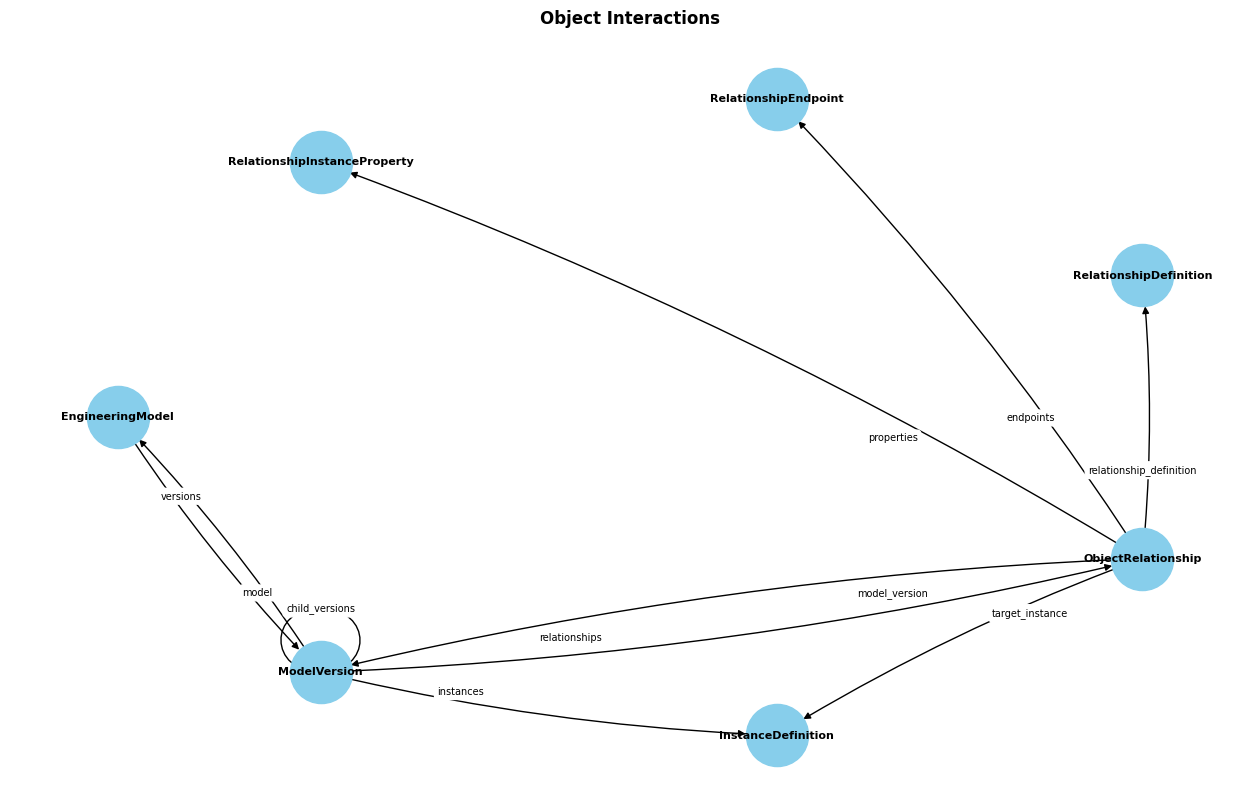

In [9]:
import networkx as nx
import matplotlib.pyplot as plt
from sqlalchemy import inspect


def plot_orm_relationships(title=None, models=None):
    G = nx.DiGraph()

    for model in models:
        mapper = inspect(model)
        G.add_node(model.__name__)

        for rel in mapper.relationships:
            G.add_edge(
                model.__name__,
                rel.mapper.class_.__name__,
                label=rel.key
            )

    pos = nx.shell_layout(G)

    plt.figure(figsize=(16, 10))

    nx.draw_networkx(
        G,
        pos,
        with_labels=True,
        node_size=2000,
        node_color="skyblue",
        font_weight="bold",
        font_size=8,
        connectionstyle="arc3,rad=0.05",
        arrows=True
    )

    edge_labels = nx.get_edge_attributes(G, "label")
    nx.draw_networkx_edge_labels(
        G,
        pos,
        edge_labels=edge_labels,
        rotate=False,
        font_size=7,
        label_pos=0.3,  # Moves label closer to the source node (0.0 = target, 1.0 = source)
    )
    if title:
        plt.title(title, fontsize=12, fontweight='bold')
    plt.axis("off")
    plt.show()

plot_orm_relationships(title='Object Interactions', models=[EngineeringModel, ModelVersion, ObjectRelationship])

In [10]:
from app.models.mbse.relationship_definition import RelationshipDefinition
from app.models.mbse.relationship_endpoint import RelationshipEndpoint
from app.models.mbse.relationship_instance_property import RelationshipInstanceProperty


inspceted_models = [
    EngineeringModel,
    ModelVersion,
    RelationshipDefinition,
    RelationshipEndpoint,
    RelationshipInstanceProperty
]

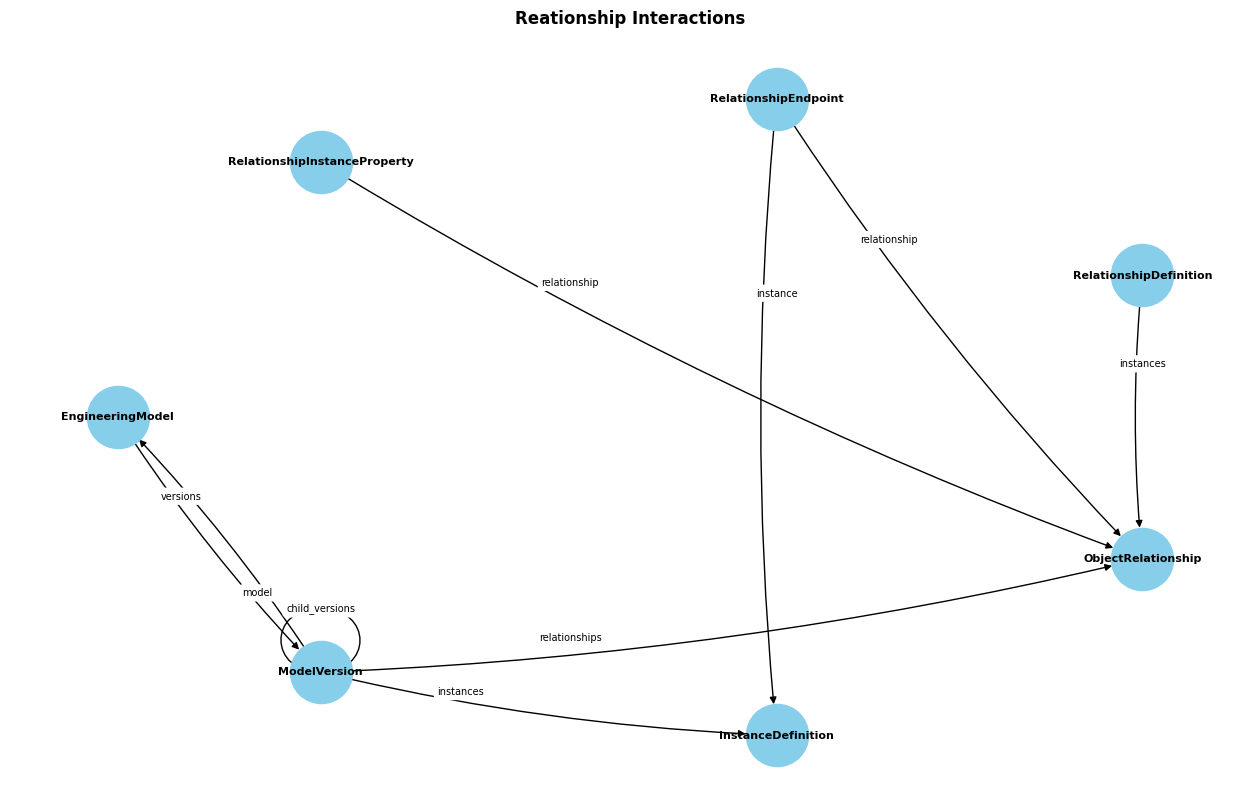

In [11]:
plot_orm_relationships(title='Reationship Interactions', models = inspceted_models)

In [12]:
from app.models.mbse.applied_stereotype import AppliedStereotype
from app.models.mbse.class_taxonomy import ClassTaxonomy
from app.models.mbse.instance_definition import InstanceDefinition
from app.models.mbse.object_definition import ObjectDefinition
from app.models.mbse.object_instance_property import ObjectInstanceProperty
from app.models.mbse.stereotype import Stereotype



inspected_models = [
    AppliedStereotype,
    ClassTaxonomy,
    InstanceDefinition,
    ModelVersion,
    ObjectDefinition,
    ObjectInstanceProperty,
    ObjectRelationship,
    RelationshipDefinition,
    RelationshipEndpoint,
    RelationshipInstanceProperty,
    Stereotype
]

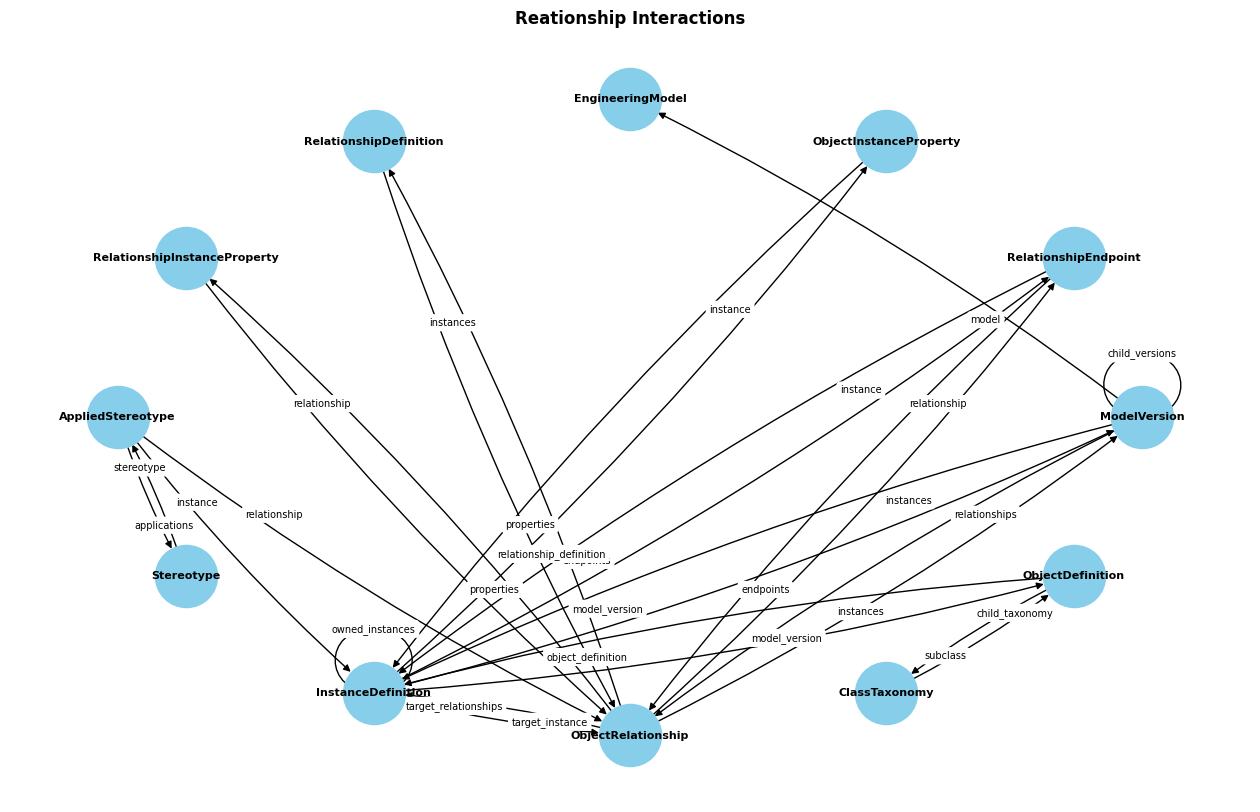

In [13]:
plot_orm_relationships(title='Reationship Interactions', models = inspected_models)

In [ ]:
df_schema 

In [29]:
import json 
data = json.loads(df_schema.to_json(orient="records", date_format="iso"))
data_table = json.loads(df_schema.to_json(orient="table", date_format="iso"))

with open('schema.json', 'w') as f:
    json.dump(data, f, indent=4)

In [22]:
type(data)

str